# The remaining models: pre-training (D), deep kernels (C), set models (E), several modules (G), better optimization (F)

The first two notebooks built the generic models (`ml_models_walkthrough.ipynb`) and the physics-structured, hierarchical ones
(`ml_structured_models.ipynb`). This one covers the rest of the list in `docs/overleaf_ml_models/ml_models.tex`, and three things
found along the way:

| Section | What |
|---|---|
| 1 | **Representation**: spectra on a logarithmic frequency axis (the largest single gain) |
| 2 | **D** self-supervised pre-training on unlabeled curves |
| 3 | **C** deep kernel learning (a CNN encoder inside a Gaussian process) |
| 4 | **E** set models: learning how to combine the 10 trace sets |
| 5 | **G** a hierarchical GP trained on several modules |
| 6 | **F** trust region, learned constraints, multi-fidelity, ParEGO |
| 7 | **Joint dark + CIC fit** of the image's per-row dark charge |
| 8 | **Real data**: does the trace predict the image's read noise? (2026-10-12) |
| 9 | Robustness over several training scans, and what to use |

Code: `src/ml/deep.py`, `setmodels.py`, `bo_advanced.py`, `structured.py` (JointLambdaGP), `benchmark_advanced.py`,
`benchmark_seeds.py`; `src/trace_features.py` and `src/stage0_trace_vs_image.py` for the real data. Everything except section 8 runs
on the synthetic world: the numbers compare methods, not the real CCD.

In [1]:
import sys, json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
from ml import synthetic, data, models, evaluate, structured as st, deep, setmodels, bo_advanced
from ml.benchmark import inputs_for, ALL_CURVES

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
RESULTS = PROJECT / "docs" / "ml_results"
FIGS = PROJECT / "docs" / "overleaf_ml_models" / "figures"
TARGETS = ["sigma_e", "lambda", "gain"]
load = lambda name: json.loads((RESULTS / name).read_text()) if (RESULTS / name).exists() else None
truth = lambda df: np.log(df[["truth.sigma_e", "truth.lambda", "truth.gain"]].to_numpy(float))

## 1. Spectra on a logarithmic frequency axis

The CDS spectrum is sampled on a linear frequency axis from 0 to 15 kHz. A noise floor (noise that does not average down with the
skips) shows only at the lowest frequencies: **2 of 256 points**. A network trained on the curves, and even more a network pre-trained
without labels, mostly ignores 2 points. On a logarithmic axis every decade gets the same number of points.

In [2]:
df, cv = synthetic.make_dataset(40, seed=3)
on = int(np.flatnonzero((df["truth.floor"] > 0.15) & (df["channel"] == 0))[0])
off = int(np.flatnonzero((df["truth.pickup"] == 0) & (df["channel"] == 0))[0])
S = cv["noise: CDS spectrum"]
f = np.linspace(0, 15, S.shape[1])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for i, label in ((on, "pickup on (floor)"), (off, "pickup off")):
    axes[0].semilogy(f, S[i], lw=0.8, label=label)
    axes[1].semilogy(data.log_frequency(S[i])[0], lw=0.8, label=label)
axes[0].set(xlabel="kHz (linear axis)", title="as stored: the floor is in the first 2 points")
axes[1].set(xlabel="point of the log-frequency curve", title="log-frequency axis: the floor spans many points")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

`data.curve_tensor(..., log_frequency_spectra=True)` does this for the models, and since 2026-10-14 the real trace features have a
curve **"noise: CDS spectrum, log frequency"** (section 8). Effect on the plain CNN (section 2's table): $\sigma_e$ error at 240 labeled
packets 10.7 % → 1.8 %.

## 2. D: self-supervised pre-training

A packet has one image but many traces, and trace-only packets are cheap. The encoder (the CNN's convolutions → 16 numbers) is first
trained **without labels** on three tasks: rebuild hidden parts of the curves (blocks of 32 points, or a whole curve), predict the
settings, and give two noisy copies of the same curves the same embedding (contrastive). Small live version (600 unlabeled packets,
8 epochs); the benchmark used 3000 packets and 40 epochs.

In [3]:
un, cu = synthetic.make_dataset(600, seed=7)
Xu, _ = inputs_for(un, cu, ("theta",), True, ALL_CURVES, log_frequency_spectra=True)
pre = deep.Pretrainer(epochs=8).fit(Xu["curves"], Xu["scalars"])
fig, ax = plt.subplots(figsize=(6, 3))
for k, v in pre.losses.items():
    ax.plot(np.array(v) / v[0], label=k)
ax.set(xlabel="epoch", ylabel="loss / first epoch", title="pre-training losses"); ax.legend(fontsize=8); plt.show()

# what the embedding knows (a probe trained on the TRUTH of unlabeled rows: a diagnostic, not a model)
from sklearn.ensemble import HistGradientBoostingRegressor
te, cte = synthetic.make_dataset(100, seed=99)
Xt, _ = inputs_for(te, cte, ("theta",), True, ALL_CURVES, log_frequency_spectra=True)
zu, zt = pre.encode(Xu["curves"]), pre.encode(Xt["curves"])
for q in ("truth.floor", "truth.state", "truth.sigma1"):
    r2 = HistGradientBoostingRegressor(max_iter=200).fit(zu, un[q]).score(zt, te[q])
    print(f"embedding -> {q:13s} R^2 = {r2:.2f}")
P = load("advanced_pretrain.json")
if P:
    print("\nbenchmark (3000 packets, 40 epochs):", {k: {q: round(v, 2) for q, v in d.items() if q != "losses"} for k, d in P["probe"].items()})

embedding -> truth.floor   R^2 = -0.37


embedding -> truth.state   R^2 = 0.84


embedding -> truth.sigma1  R^2 = 0.98

benchmark (3000 packets, 40 epochs): {'linear-frequency spectra': {'truth.floor': 0.08, 'truth.state': 0.97, 'truth.sigma1': 0.99}, 'log-frequency spectra': {'truth.floor': 0.71, 'truth.state': 0.97, 'truth.sigma1': 0.99}}


sigma_e error against the truth (%), by number of labeled packets


,30,60,120,240
CNN from scratch (first round),15.6,13.6,12.5,10.7
"CNN from scratch, log-frequency spectra",10.7,7.1,4.5,1.8
D: pre-trained encoder frozen + NN ensemble,9.4,7.8,5.2,4.6
D: pre-trained encoder fine-tuned,11.0,6.9,3.4,2.2
"C: deep kernel GP, pre-trained encoder frozen",13.3,10.3,5.5,4.6
"C: deep kernel GP, pre-trained encoder fine-tuned",7.7,5.4,2.9,2.4


68 % coverage of sigma_e (target 0.68)


,30,60,120,240
CNN from scratch (first round),0.60,0.53,0.65,0.67
"CNN from scratch, log-frequency spectra",0.71,0.61,0.84,0.81
D: pre-trained encoder frozen + NN ensemble,0.65,0.64,0.64,0.69
D: pre-trained encoder fine-tuned,0.65,0.76,0.71,0.78
"C: deep kernel GP, pre-trained encoder frozen",0.54,0.73,0.73,0.72
"C: deep kernel GP, pre-trained encoder fine-tuned",0.11,0.10,0.08,0.09


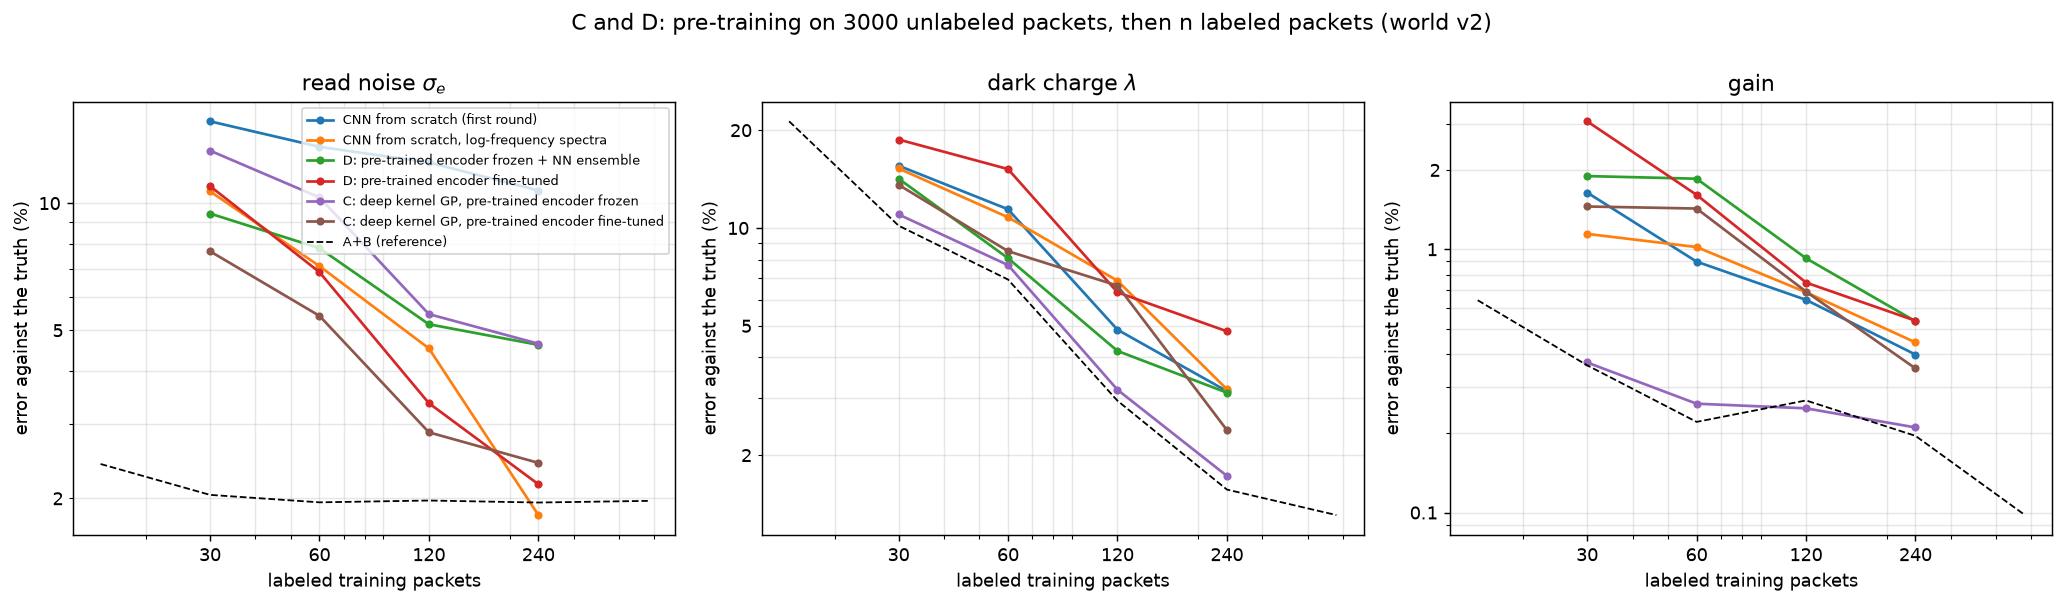

In [4]:
if P:
    tab = {label: {int(n): 100 * r["truth"]["sigma_e"]["rel_error"] for n, r in by_n.items()} for label, by_n in P["learning"].items()}
    cov = {label: {int(n): r["labels"]["sigma_e"]["coverage"] for n, r in by_n.items()} for label, by_n in P["learning"].items()}
    print("sigma_e error against the truth (%), by number of labeled packets"); display(pd.DataFrame(tab).T.round(1))
    print("68 % coverage of sigma_e (target 0.68)"); display(pd.DataFrame(cov).T.round(2))
    display(Image(str(FIGS / "ml_advanced_pretrain.png"), width=950))

**Reading it:** the small live pre-training (600 packets, 8 epochs) learns the state and the single-skip noise but not yet the
floor; the benchmark's 3000 packets and 40 epochs do (probe $R^2$ 0.71 with log-frequency spectra, 0.08 without). In the table, the
log-frequency representation alone is the largest gain. Pre-training helps when labels are few (30–120
packets); a frozen encoder caps the accuracy, fine-tuning removes the cap.

## 3. C: deep kernel learning

A Gaussian process on $z = (\text{encoder(curves)}, \theta, \text{state})$ with an amplifier offset term. The encoder starts from D.
**Frozen**, the GP's error bars stay calibrated; **fine-tuned** with the GP on few packets, the encoder bends the space until the GP is
sure of itself (coverage ~0.1 in the benchmark). Live, frozen, 60 labeled packets:

In [5]:
tr, ctr = synthetic.make_dataset(60, seed=1)
prep = st.StructuredPrep(own_features=()).fit(tr)
P_tr, P_te = prep.transform(tr, ctr), prep.transform(te, cte)
C_tr, _ = inputs_for(tr, ctr, ("theta",), True, ALL_CURVES, log_frequency_spectra=True)
dkl = deep.DeepKernelGP(pre, finetune=False, steps=150).fit({"curves": C_tr["curves"], "x": P_tr["x"], "amp": P_tr["amp"]}, data.make_targets(tr)[0])
m, s = dkl.predict({"curves": Xt["curves"], "x": P_te["x"], "amp": P_te["amp"]})
sc = evaluate.scores(truth(te), m, s, TARGETS)
print({t: f"{100 * sc[t]['rel_error']:.1f} % (coverage {sc[t]['coverage']:.2f})" for t in TARGETS})

{'sigma_e': '13.2 % (coverage 0.56)', 'lambda': '4.7 % (coverage 0.88)', 'gain': '0.2 % (coverage 1.00)'}


## 4. E: set models

**World v4**: an outside source is on during only some of the 10 trace sets (the image sees its time average), and 10 % of the sets
are damaged. A plain mean is dragged by the damaged sets; a median picks "on" or "off" and loses the time average. The set network
(DeepSets with attention pooling) reads every set's Allan deviation and learns the combination, inside A+B.

In [6]:
d4, c4 = synthetic.make_dataset(60, seed=1, within_packet_pickup=True, damaged_fraction=0.1)
i = int(np.flatnonzero((d4["truth.duty"] > 0.3) & (d4["truth.duty"] < 0.8) & (d4["truth.n_damaged"] > 0))[0])
fig, ax = plt.subplots(figsize=(6, 3.4))
for k, curve in enumerate(c4["sets: noise: Allan deviation"][i]):
    ax.loglog(synthetic.ALLAN_N, curve, lw=0.8, color="0.6")
ax.loglog(synthetic.ALLAN_N, np.mean(c4["sets: noise: Allan deviation"][i], 0), "r-", lw=2, label="mean of the sets")
ax.loglog(synthetic.ALLAN_N, np.median(c4["sets: noise: Allan deviation"][i], 0), "b--", lw=2, label="median")
ax.set(xlabel="skips averaged", ylabel="Allan deviation (ADU)", title=f"one packet: 10 trace sets (pickup duty {d4['truth.duty'][i]:.2f})")
ax.legend(fontsize=8); plt.show()

E = load("advanced_sets.json")
if E:
    tab = {comb: {int(n): f"{100 * np.mean([r['truth']['sigma_e']['rel_error'] for r in rs]):.1f}" for n, rs in by_n.items()} for comb, by_n in E.items()}
    print("sigma_e error against the truth (%), mean of 2 training scans"); display(pd.DataFrame(tab).T)

sigma_e error against the truth (%), mean of 2 training scans


,30,60,120,240
mean,32.6,35.4,34.3,32.1
median,5.1,6.5,4.4,3.7
robust mean,4.8,7.5,3.9,3.4
mean of variances,41.9,47.2,43.6,41.9
robust mean of variances,4.9,6.7,3.8,3.5
learned,5.6,4.8,3.3,3.1


The learned combination is about as good as a **robust** fixed rule (the processing pipeline's robust mean), with conservative error
bars. With two training scans the ranking at 30–60 packets changed, so a single scan is not enough to choose (section 9).

## 5. G: several modules

The hierarchical GP's module-level variance can only be learned from several modules. Trained on 4 modules instead of 1, the errors on
a fifth were the same, and with none of its packets its error bars were *worse* (in this toy world the noisy amplifier sits on the same
channel of every module, a pattern a module/amplifier hierarchy does not represent). G will be judged on real modules.

In [7]:
G = load("advanced_modules.json")
if G:
    tab = {name: {f"k={k}": f"{100 * r['truth']['sigma_e']['rel_error']:.1f} % (cov {r['labels']['sigma_e']['coverage']:.2f})" for k, r in by_k.items()}
           for name, by_k in G.items()}
    display(pd.DataFrame(tab).T)

,k=0,k=1,k=2,k=5
"B: hierarchical GP, trained on 1 module",61.3 % (cov 0.35),13.8 % (cov 0.76),15.0 % (cov 0.66),13.9 % (cov 0.61)
"A+B: physics + hierarchical GP, trained on 1 module",32.6 % (cov 0.74),2.1 % (cov 0.70),1.9 % (cov 0.69),1.9 % (cov 0.71)
"B: hierarchical GP, trained on 4 modules",62.6 % (cov 0.28),13.7 % (cov 0.75),14.7 % (cov 0.65),13.2 % (cov 0.62)
"A+B: physics + hierarchical GP, trained on 4 modules",34.8 % (cov 0.40),2.0 % (cov 0.71),1.9 % (cov 0.75),1.8 % (cov 0.76)


## 6. F: better optimization

All strategies use the decomposed surrogate (one GP for $\log\sigma_e$, one for $\log\lambda$). Live: 25 packets of the global search
and of the trust region (one repeat); then the benchmark (5 repeats, 40 packets).

global        best true J after 25 packets: -2.772


trust region  best true J after 25 packets: -2.774
random        best true J after 25 packets: -2.520


,J at cost 20,J at cost 40,failed packets,hypervolume
global (decomposed surrogate),-2.784,-2.806,0.0,0.164
trust region,-2.775,-2.836,0.0,NaN
learned constraint,-2.738,-2.800,7.0,NaN
no constraint,-2.754,-2.806,10.2,NaN
"multi-fidelity, trace = 0.25 packet",-2.760,-2.806,0.0,NaN
"multi-fidelity, trace = 0.5 packet",-2.739,-2.802,0.0,NaN
ParEGO (multi-objective),-2.784,-2.795,0.0,0.161
random,-2.556,-2.665,0.0,0.091


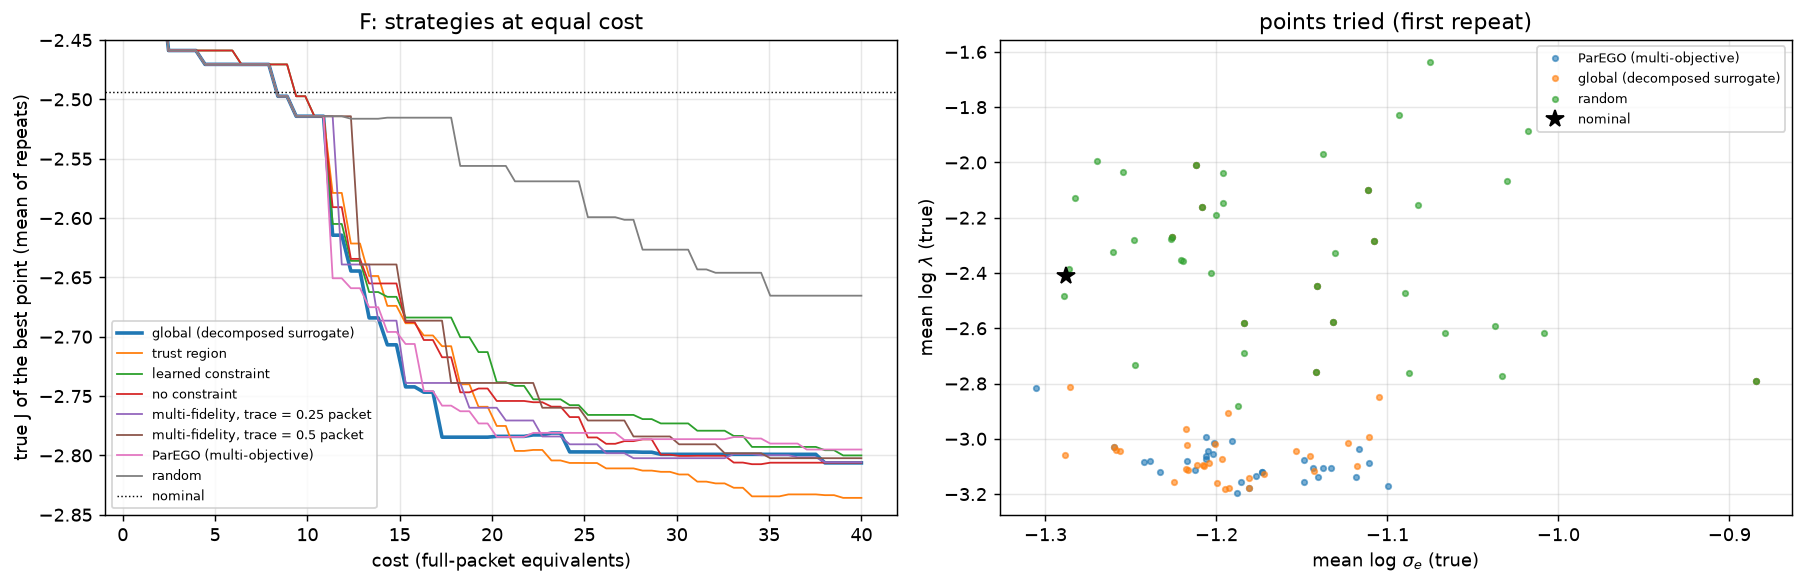

In [8]:
for strategy in ("global", "trust region", "random"):
    r = bo_advanced.run(strategy, seed=0, n_total=25, budget=25)
    print(f"{strategy:13s} best true J after 25 packets: {r['best_true'][-1]:.3f}")
B = load("advanced_bo.json")
if B:
    def best_at(r, c):
        k = int(np.searchsorted(r["costs"], c + 1e-9)); return r["best_true"][k - 1] if k else np.nan
    rows = {label: {"J at cost 20": np.mean([best_at(r, 20) for r in runs]), "J at cost 40": np.mean([r["best_true"][-1] for r in runs]),
                    "failed packets": np.mean([r["failures"] for r in runs]),
                    "hypervolume": np.mean([r["hypervolume"] for r in runs]) if "hypervolume" in runs[0] else np.nan}
            for label, runs in B["results"].items()}
    display(pd.DataFrame(rows).T.round(3))
    display(Image(str(FIGS / "ml_advanced_bo.png"), width=950))

* **Trust region**: the best settings after 40 packets; it refines locally once near the optimum, and suits bounded voltage steps.
* **Learned constraint**: still wasted packets, so the known limits belong in `ccd_limits.py`.
* **Multi-fidelity** and **ParEGO** gave nothing here: the objective's gain comes from $\lambda$, which traces cannot measure, and
  $\sigma_e$ and $\lambda$ barely conflict in this world.

## 7. Joint fit of dark current and CIC

With EXPOSURE 0 the dark charge of row $r$ is $\lambda_r = \text{CIC} + \text{DC}\,(r+\tfrac12)/8$. A straight line through the 16
rows gives DC and CIC, each to ~13 %, but **strongly anti-correlated** (a line's slope against its intercept): their sum is known to
3 %. Fitting the two parts separately threw that away and was worse than fitting $\lambda$ directly. `JointLambdaGP` models
$\log$ DC and $\log$ CIC together with each image's exact 2×2 covariance:

In [9]:
cov = st.line_fit_covariance(np.array([0.03]), np.array([0.04]))[0]
print("one image (DC 0.03, CIC 0.04 e-/pixel): sd DC %.4f, sd CIC %.4f, correlation %.2f, sd of the sum %.4f"
      % (np.sqrt(cov[0, 0]), np.sqrt(cov[1, 1]), cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1]), np.sqrt(cov.sum())))
kw = {"image_only_noise": True, "per_row_lambda": True}
tr3, c3 = synthetic.make_dataset(120, seed=1, **kw); te3, ct3 = synthetic.make_dataset(150, seed=99, **kw)
prep3 = st.StructuredPrep(own_features=()).fit(tr3); X3, Xt3 = prep3.transform(tr3, c3), prep3.transform(te3, ct3)
for lm in ("direct", "split", "joint"):
    m, s = st.PhysicsStructured("hier", lambda_model=lm).fit(X3, data.make_targets(tr3)[0], st.component_targets(tr3)).predict(Xt3)
    sc = evaluate.scores(truth(te3), m, s, TARGETS)
    print(f"lambda {lm:6s}: error {100 * sc['lambda']['rel_error']:4.1f} %  (68 % coverage against the labels "
          f"{np.mean(np.abs(m[:, 1] - data.make_targets(te3)[0][:, 1]) <= s[:, 1]):.2f})")
L = load("seeds_summary_lambda.json")
if L and "lambda" in L:
    print("\nover several training scans (mean +- sd, %):")
    display(pd.DataFrame({k: {lab: f"{e['lambda'][0]:.1f} +- {e['lambda'][1]:.1f}" for lab, e in v.items()} for k, v in L["lambda"].items()}))

one image (DC 0.03, CIC 0.04 e-/pixel): sd DC 0.0038, sd CIC 0.0034, correlation -0.83, sd of the sum 0.0022


lambda direct: error  2.5 %  (68 % coverage against the labels 0.73)


lambda split : error  2.7 %  (68 % coverage against the labels 0.99)


lambda joint : error  2.0 %  (68 % coverage against the labels 0.69)

over several training scans (mean +- sd, %):


,n=30,n=60,n=120,n=240
"A+B, lambda direct",13.5 +- 3.7,5.4 +- 0.6,3.1 +- 0.8,1.8 +- 0.3
"A+B, lambda split",16.9 +- 10.2,6.3 +- 2.3,3.9 +- 1.3,2.8 +- 0.8
"A+B, lambda joint",14.8 +- 9.3,4.8 +- 1.9,3.1 +- 1.3,1.6 +- 0.3


The joint fit is better than the separate split at every size and calibrated; it beats fitting $\lambda$ directly only with enough
packets (~240), because two GPs with their own inputs need more data than one.

## 8. Real data: does the trace predict the image's read noise?

The 2026-10-12 run has traces and (binned 20×20) images at the same five settings on module 101. `src/stage0_trace_vs_image.py`
fits $\sigma_A(n)^2 = a^2/n + b^2$ to each trace set's Allan deviation and compares $\sqrt{a^2/500 + b^2}$ with the image's overscan
noise. Two versions of the Allan curve:

* the **detrended** one (the original feature): a degree-4 polynomial removes the slowest noise, and its long-block points are biased low;
* the new one (2026-10-14), **"common pattern removed"**: each pixel's CDS minus the mean of all pixels at the same skip, nothing else
  removed. The pattern every pixel shares is not noise for an image; the slow noise that differs between pixels is.

In [10]:
from trace_features import trace_features, ALLAN_N
RUN = PROJECT / "data" / "2026-10-12-PA03_PQ04_Packet_Tests"
paths = sorted(RUN.glob("trace_*_ch0_101_*.meta"))[3:9]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, p in enumerate(paths):
    f = trace_features(p.with_suffix(".RJ45ADCDATA0"), meta=json.loads(p.read_text()))
    white = f.scalars["skip: CDS rms (detrended)"] / np.sqrt(ALLAN_N)
    ax.semilogx(ALLAN_N, f.curves["noise: Allan deviation"] / white, "o-", color="tab:blue", ms=3, lw=0.8, label="detrended" if k == 0 else None)
    ax.semilogx(ALLAN_N, f.curves["noise: Allan deviation, common pattern removed"] / white, "s-", color="tab:red", ms=3, lw=0.8,
                label="common pattern removed" if k == 0 else None)
ax.axhline(1, color="k", lw=0.8)
ax.set(xlabel="skips averaged n", ylabel="Allan deviation / white-noise value", title="real traces, module 101 ch0 (2026-10-12)")
ax.legend(fontsize=8); plt.show()

In [11]:
out = subprocess.run([sys.executable, str(PROJECT / "src" / "stage0_trace_vs_image.py")], capture_output=True, text=True, cwd=PROJECT / "src")
print("\n".join(line for line in out.stdout.splitlines()[:22]))

detrended curve (n <= 100) | curve with the common pattern removed (all n) | image
set ch NCOLPRE  CDS rms       a      b   → 500 |      a      b   → 500 | overscan  ratio  ratio
  1  0       0     5.71    5.36  0.000   0.240 |   5.41  0.025   0.246 |    0.583   2.43   2.37
  1  1       0     5.97    5.87  0.159   0.325 |   5.63  0.000   0.252 |    1.814   5.57   7.21
  1  2       0    22.44   17.57  0.000   0.786 |  20.83  0.000   0.932 |    1.977   2.52   2.12
  1  3       0     6.61    6.23  0.000   0.278 |   6.42  0.000   0.287 |    1.503   5.40   5.23
  2  0     185     5.78    5.57  0.085   0.285 |   5.41  0.430   0.493 |    0.662   2.32   1.34
  2  1     185     5.89    5.81  0.165   0.313 |   5.57  0.361   0.439 |    1.617   5.17   3.68
  2  2     185    24.69   20.06  0.000   0.897 |  22.80  0.258   1.105 |    1.555   1.73   1.41
  2  3     185     6.63    6.53  0.130   0.356 |   6.36  0.278   0.431 |    1.521   4.27   3.53
  3  0     185     5.67    5.43  0.000   0.243 |   5.

* With the new curve the traces show a **floor**: white up to ~50 skips, then 1.15–1.5 times the white value.
* Against the **binned** 500-skip overscan, ch0's ratio is 0.9–1.3 for the 1.7-s traces (1.2–2.3 with the detrended curve); the 0.8-s
  traces of setting 1 see no floor: a trace must last long enough to see slow noise. ch1 and ch3 remain 3–8 times noisier there.
* The cleaner test is the **1×1, 3000-skip image of 2026-10-06** (section 8b): there the traces predict ch1 within 5 %, but ch0 25 %
  too low and ch3 45–50 % too high. At 3000 skips the floor dominates, and 500-skip traces of 10 pixels measure it poorly.

## 8b. Do the models need to be told which amplifier they predict?

Most models were given the amplifier identity, because the toy amplifiers differ a lot. That ties a model to the amplifiers it was
trained on. `src/ml/benchmark_amp.py` compares explicit identity, *implicit* identity (the amplifier's own trace and reference
features, no ID) and no amplifier information at all, on known amplifiers and on a never-seen module, with three scores: the usual
error, the **shape** error (each amplifier's own offset removed: is the dependence on the settings right?) and the **rank**
correlation within each amplifier (does it order the settings correctly, which is what an optimizer needs).

In [12]:
A = load("amp_information_summary.json")
if A:
    for key, by_label in A.items():
        print(f"--- {key}: error abs / shape (%) and within-amplifier rank")
        display(pd.DataFrame({t: {lab: f"{100 * e[t]['abs']:.1f} / {100 * e[t]['shape']:.1f} / {e[t]['rank']:.2f}" for lab, e in by_label.items()}
                              for t in TARGETS}))

--- known amplifiers: error abs / shape (%) and within-amplifier rank


,sigma_e,lambda,gain
GP: settings + amplifier ID,17.4 / 17.1 / 0.47,23.4 / 22.9 / 0.74,0.5 / 0.4 / 0.98
GP: settings + amplifier ID + features,12.2 / 11.9 / 0.70,2.2 / 2.1 / 1.00,0.2 / 0.2 / 0.99
GP: settings + features (no ID),12.1 / 11.8 / 0.70,2.2 / 2.2 / 1.00,0.2 / 0.2 / 0.99
GP: settings only (no amplifier information),60.3 / 14.7 / 0.27,22.3 / 21.8 / 0.77,31.3 / 2.0 / 0.07
CNN: settings + curves (no ID),1.7 / 1.6 / 0.99,3.0 / 2.9 / 1.00,0.5 / 0.4 / 0.98
A+B: physics + hierarchical GP (amplifier levels),1.7 / 1.7 / 0.99,1.6 / 1.6 / 1.00,0.2 / 0.1 / 1.00
"A: physics, no amplifier information",31.4 / 2.6 / 0.98,1.6 / 1.6 / 1.00,31.3 / 2.0 / 0.84
A: physics + own features (no ID),1.8 / 1.8 / 0.99,1.8 / 1.8 / 1.00,0.2 / 0.2 / 0.99


--- new module, k=0: error abs / shape (%) and within-amplifier rank


,sigma_e,lambda,gain
GP: settings + amplifier ID,62.1 / 12.9 / 0.42,23.9 / 23.3 / 0.77,33.0 / 2.0 / 0.98
GP: settings + amplifier ID + features,95.2 / 13.1 / 0.36,96.5 / 23.5 / 0.84,31.9 / 1.2 / 1.00
GP: settings + features (no ID),76.7 / 12.3 / 0.42,175.7 / 22.5 / 0.76,22.1 / 0.3 / 0.99
GP: settings only (no amplifier information),59.5 / 13.5 / 0.23,22.3 / 21.8 / 0.77,33.0 / 2.0 / 0.07
CNN: settings + curves (no ID),9.0 / 2.8 / 0.97,3.5 / 3.3 / 1.00,13.1 / 0.9 / 0.94
A+B: physics + hierarchical GP (amplifier levels),33.1 / 2.0 / 0.98,7.0 / 5.7 / 1.00,33.5 / 1.4 / 1.00
"A: physics, no amplifier information",33.5 / 2.7 / 0.97,1.6 / 1.6 / 1.00,33.4 / 2.0 / 0.84
A: physics + own features (no ID),29.6 / 2.0 / 0.98,2.9 / 2.3 / 1.00,29.7 / 0.7 / 0.96


--- new module, k=2: error abs / shape (%) and within-amplifier rank


,sigma_e,lambda,gain
GP: settings + amplifier ID,37.9 / 17.7 / 0.12,34.5 / 34.1 / 0.17,3.1 / 1.8 / 0.26
GP: settings + amplifier ID + features,19.2 / 15.1 / 0.08,38.0 / 34.8 / 0.10,3.1 / 1.8 / 0.26
GP: settings + features (no ID),16.5 / 12.9 / 0.45,27.9 / 23.1 / 0.72,0.9 / 0.3 / 0.99
GP: settings only (no amplifier information),59.4 / 13.0 / 0.44,22.7 / 22.1 / 0.77,33.6 / 2.0 / 0.17
CNN: settings + curves (no ID),9.3 / 3.0 / 0.96,3.5 / 3.3 / 0.99,10.4 / 1.1 / 0.89
A+B: physics + hierarchical GP (amplifier levels),2.0 / 1.9 / 0.98,1.6 / 1.6 / 1.00,0.5 / 0.2 / 1.00
"A: physics, no amplifier information",33.5 / 2.7 / 0.97,1.6 / 1.6 / 1.00,33.4 / 2.0 / 0.81
A: physics + own features (no ID),2.2 / 1.9 / 0.98,2.9 / 2.3 / 1.00,1.1 / 0.6 / 0.97


**Result (synthetic, 3 training scans):** with the amplifier's own traces the label adds almost nothing ($\sigma_e$ 1.8 vs 1.7 % on
known amplifiers, 2.2 vs 2.0 % on a new module after 2 of its packets). Without any amplifier information the level is wrong (the gain)
but the shape (~2.6 %) and the order of the settings (0.98) stay right. For a never-seen amplifier every model is off by its gain in
absolute terms, while the physics models keep shape and order. **This is now the default model**: `PhysicsStructured()` with
`StructuredPrep()` (no identity, own trace and reference features).

**On the real amplifiers** (module 101, `src/real_amplifier_check.py`):

* **gains** from the electron peaks of the 2026-10-06 1×1 image differ by only 2 % between ch0, ch1 and ch3 (ch2's peaks are not
  resolved), so using the other channels' mean gain instead of a label costs 1.5–4.4 %;
* **responses**: the changes of the 85 features with the settings agree in sign 86–99 % between channels (correlation 0.85–0.96), but the
  noise of ch2 changes alone, which a model sees in ch2's own trace without any label;
* **noise from the trace: an extrapolation check only.** A 500-skip trace and a 3000-skip image are not directly comparable: the fit
  uses blocks of at most 100–160 skips and is evaluated at 3000, where the floor dominates. It is off by −25 to +45 %, with or without the
  label. The real test needs the planned packets (1×1, 500 skips, matched traces minutes apart).

In [13]:
R2 = load("real_amplifier_check.json")
if R2:
    display(pd.DataFrame(R2["image"]).T.round(3))
    display(pd.DataFrame(R2["traces"]).T[["white", "detrended", "common removed", "n_traces"]].round(3))
    print("sign agreement of the setting responses between channels:", {k: round(v, 2) for k, v in R2["responses"]["sign agreement"].items()})

,gain,sigma_adu,sigma_e,n_peaks
0,1.31,0.134,0.102,12.0
1,1.30,0.129,0.099,12.0
2,0.76,0.739,0.972,23.0
3,1.25,0.157,0.125,12.0


,white,detrended,common removed,n_traces
0,0.102,0.091,0.098,5.0
1,0.107,0.121,0.122,6.0
2,1.985,1.439,1.842,6.0
3,0.122,0.117,0.238,6.0


sign agreement of the setting responses between channels: {'ch0-ch1': 0.99, 'ch0-ch2': 0.86, 'ch0-ch3': 0.88, 'ch1-ch2': 0.91, 'ch1-ch3': 0.97, 'ch2-ch3': 0.88}


## 9. Robustness over training scans, and what to use

Most benchmarks used one training scan. `benchmark_seeds.py` repeats the key comparisons over 5 scans:

In [14]:
R = load("seeds_summary.json")
if R:
    for exp, by_key in R.items():
        print(f"--- {exp}: error against the truth, mean +- sd (%)")
        display(pd.DataFrame({key: {lab: f"σe {e['sigma_e'][0]:.1f}±{e['sigma_e'][1]:.1f} | λ {e['lambda'][0]:.1f}±{e['lambda'][1]:.1f}"
                                    for lab, e in v.items()} for key, v in by_key.items()}))
else:
    print("seeds_summary.json not there yet: run  cd src && ../.venv/bin/python -m ml.benchmark_seeds")

--- design: error against the truth, mean +- sd (%)


,one-at-a-time,random,half and half
"first round: GP, theta + amp + features",σe 14.8±1.1 | λ 10.3±1.7,σe 13.2±1.3 | λ 1.9±0.2,σe 14.1±0.6 | λ 2.8±0.5
A+B,σe 2.3±0.2 | λ 12.6±0.3,σe 1.9±0.0 | λ 1.6±0.2,σe 2.0±0.0 | λ 2.4±0.4


--- newmodule: error against the truth, mean +- sd (%)


,k=0,k=1,k=2,k=5
"first round: GP, theta + amp + features",σe 77.6±39.3 | λ 103.2±17.9,σe 26.6±4.1 | λ 39.3±2.7,σe 20.2±4.2 | λ 42.2±3.0,σe 18.8±3.5 | λ 37.0±2.1
B: hierarchical GP,σe 57.8±0.2 | λ 19.3±15.4,σe 9.2±2.2 | λ 1.7±1.1,σe 7.7±0.7 | λ 1.2±0.2,σe 7.2±0.9 | λ 1.3±0.3
A+B,σe 33.2±0.2 | λ 19.3±15.4,σe 2.9±0.4 | λ 1.7±1.1,σe 2.6±0.8 | λ 1.2±0.2,σe 1.8±0.0 | λ 1.3±0.3


--- sets: error against the truth, mean +- sd (%)


,n=30,n=60,n=120
median,σe 4.4±0.8 | λ 10.7±1.9,σe 4.9±2.3 | λ 5.5±0.6,σe 6.7±3.0 | λ 3.9±0.7
robust mean,σe 4.0±0.8 | λ 10.7±1.9,σe 5.2±3.2 | λ 5.5±0.6,σe 6.9±3.9 | λ 3.9±0.7
robust mean of variances,σe 4.2±0.9 | λ 10.7±1.9,σe 4.9±2.6 | λ 5.5±0.6,σe 7.3±4.5 | λ 3.9±0.7
learned,σe 6.3±1.6 | λ 10.7±1.9,σe 4.1±1.1 | λ 5.5±0.6,σe 3.7±0.5 | λ 3.9±0.7


--- learning: error against the truth, mean +- sd (%)


,v2 n=15,v2 n=60,v2 n=240,v3 n=15,v3 n=60,v3 n=240
"first round: GP, theta + amp + features",σe 17.1±1.7 | λ 28.9±7.0,σe 13.6±1.3 | λ 3.7±1.2,σe 12.0±0.4 | λ 1.9±0.2,σe 15.6±2.0 | λ 25.3±7.9,σe 12.6±1.1 | λ 4.1±1.0,σe 10.0±0.2 | λ 2.4±0.2
B: hierarchical GP,σe 17.0±0.6 | λ 24.0±3.7,σe 16.2±1.7 | λ 5.6±2.5,σe 13.3±0.6 | λ 1.5±0.1,σe 13.5±1.5 | λ 30.5±5.8,σe 13.0±0.9 | λ 6.0±1.2,σe 11.4±0.7 | λ 1.8±0.3
A+B,σe 2.3±0.2 | λ 24.0±3.7,σe 2.0±0.1 | λ 5.6±2.5,σe 1.9±0.0 | λ 1.5±0.1,σe 3.5±0.3 | λ 30.5±5.8,σe 2.9±0.3 | λ 6.0±1.2,σe 2.3±0.0 | λ 1.8±0.3
"CNN, curves + theta + amp",NaN,σe 12.4±0.4 | λ 13.8±3.1,σe 6.7±1.8 | λ 3.8±0.2,NaN,σe 10.4±0.1 | λ 17.6±2.2,σe 5.9±1.2 | λ 4.8±0.4
"CNN, log-frequency spectra",NaN,σe 7.9±3.1 | λ 18.4±6.9,σe 1.6±0.2 | λ 3.8±0.2,NaN,σe 5.2±0.6 | λ 18.8±2.4,σe 1.8±0.1 | λ 4.7±0.5


**What to use on the first real scan**

* **Predictor:** A+B (physics-structured, hierarchical GP) with conformal error bars (H); the noise from the trace's
  common-pattern-removed Allan curve; $\lambda$ directly, switching to the joint dark + CIC fit once there are a few hundred packets.
* **Optimizer:** the decomposed surrogate in a trust region, with the known limits encoded.
* **Scan:** the mixed design (`scan_packets.py`, `type = "mixed"`; example `configs/scan_mixed_example.toml`).
* **Later, with many real traces:** pre-training (D) and a frozen deep kernel (C); set models (E) if the trace sets turn out to differ in
  ways no fixed rule handles; G when there are several modules.